# Basic Forecasting Methods
Naiive Forecast, Simple Average Forecast, Moving Average Forecast, Weighted Moving Average Forecast

# Imports and Data Generation

In [11]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

In [12]:
#Generate sample data for basic forecasting example
#Monthly data for 5 years, data roughly constant, with small random fluctuations
np.random.seed(0)
date_rng = pd.date_range(start='1/1/2015', end='12/31/2019', freq='M')
data = pd.DataFrame(date_rng, columns=['date'])
data['Sales_Actuals'] = 100000 + 1000*(np.random.normal(0, 5, len(data)))
#round to integer
data['Sales_Actuals'] = data['Sales_Actuals'].round().astype(int)
data = data.set_index('date')
data.head()

/var/folders/97/0jjhtb3j79jfj093mf3zb5vh0000gq/T/ipykernel_71123/794067782.py:4: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  date_rng = pd.date_range(start='1/1/2015', end='12/31/2019', freq='M')


,Sales_Actuals
date,
2015-01-31,108820
2015-02-28,102001
2015-03-31,104894
2015-04-30,111204
2015-05-31,109338


# Naiive Forecast

In [13]:
#Calculate naive forecast
data['Naive_Forecast'] = data['Sales_Actuals'].shift(1)
data.head()

,Sales_Actuals,Naive_Forecast
date,,
2015-01-31,108820,NaN
2015-02-28,102001,108820.0
2015-03-31,104894,102001.0
2015-04-30,111204,104894.0
2015-05-31,109338,111204.0


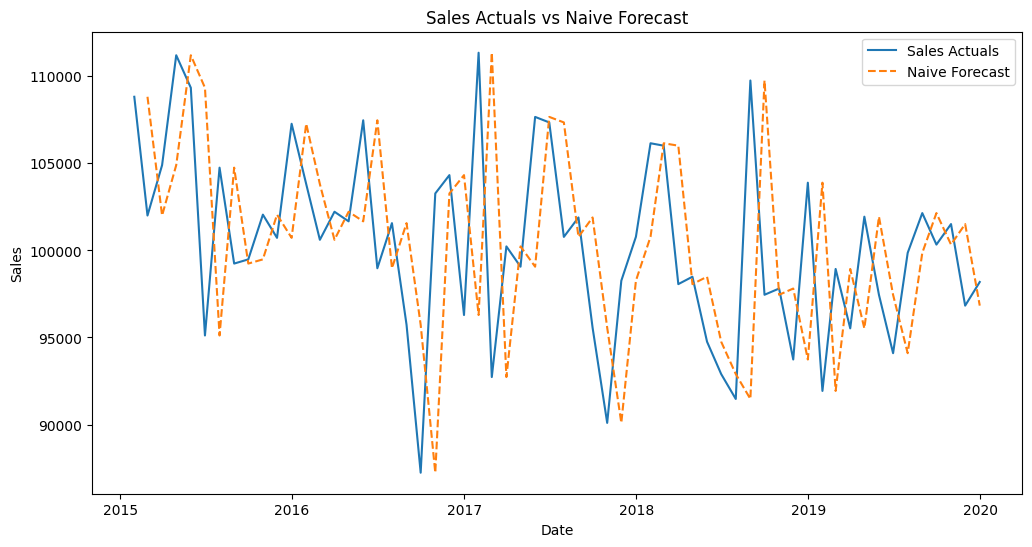

In [14]:
#plot sales actuals and naive forecast
plt.figure(figsize=(12,6))
plt.plot(data.index, data['Sales_Actuals'], label='Sales Actuals')
plt.plot(data.index, data['Naive_Forecast'], label='Naive Forecast', linestyle='--')
plt.title('Sales Actuals vs Naive Forecast')
plt.xlabel('Date')
plt.ylabel('Sales')
plt.legend()
plt.show()

# Simple Average Forecast

In [15]:
#calculate simple average forecast
data['Simple_Average_Forecast'] = data['Sales_Actuals'].expanding().mean().shift(1)
data.head()
#place columns in order: Sales_Actuals, Simple_Average_Forecast, Naive_Forecast
data = data[['Sales_Actuals', 'Simple_Average_Forecast', 'Naive_Forecast']]
data.head()

,Sales_Actuals,Simple_Average_Forecast,Naive_Forecast
date,,,
2015-01-31,108820,NaN,NaN
2015-02-28,102001,108820.000000,108820.0
2015-03-31,104894,105410.500000,102001.0
2015-04-30,111204,105238.333333,104894.0
2015-05-31,109338,106729.750000,111204.0


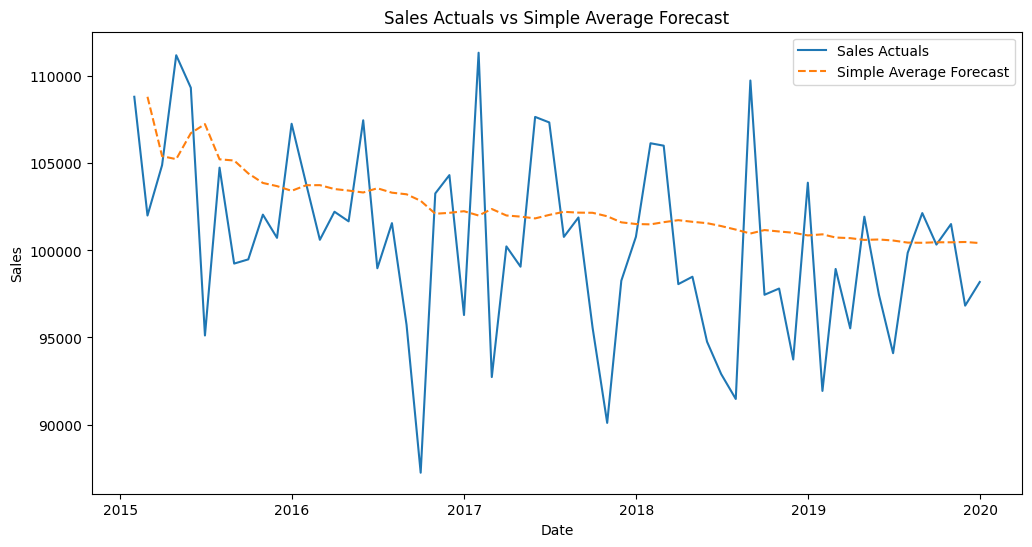

In [16]:
#plot simple average forecast vs sales actuals
plt.figure(figsize=(12,6))
plt.plot(data.index, data['Sales_Actuals'], label='Sales Actuals')
plt.plot(data.index, data['Simple_Average_Forecast'], label='Simple Average Forecast', linestyle='--')
plt.title('Sales Actuals vs Simple Average Forecast')
plt.xlabel('Date')
plt.ylabel('Sales')
plt.legend()
plt.show()

# Moving Average Forecast

In [17]:
#calculate moving average forecast with window size 3
data['Moving_Average_Forecast'] = data['Sales_Actuals'].rolling(window=3).mean().shift(1)
data.head()
#place columns in order: Sales_Actuals, Moving_Average_Forecast, Simple_Average_Forecast, Naive_Forecast
data = data[['Sales_Actuals', 'Moving_Average_Forecast', 'Simple_Average_Forecast', 'Naive_Forecast']]
data.head(10) 

,Sales_Actuals,Moving_Average_Forecast,Simple_Average_Forecast,Naive_Forecast
date,,,,
2015-01-31,108820,NaN,NaN,NaN
2015-02-28,102001,NaN,108820.000000,108820.0
2015-03-31,104894,NaN,105410.500000,102001.0
2015-04-30,111204,105238.333333,105238.333333,104894.0
2015-05-31,109338,106033.000000,106729.750000,111204.0
2015-06-30,95114,108478.666667,107251.400000,109338.0
2015-07-31,104750,105218.666667,105228.500000,95114.0
2015-08-31,99243,103067.333333,105160.142857,104750.0
2015-09-30,99484,99702.333333,104420.500000,99243.0


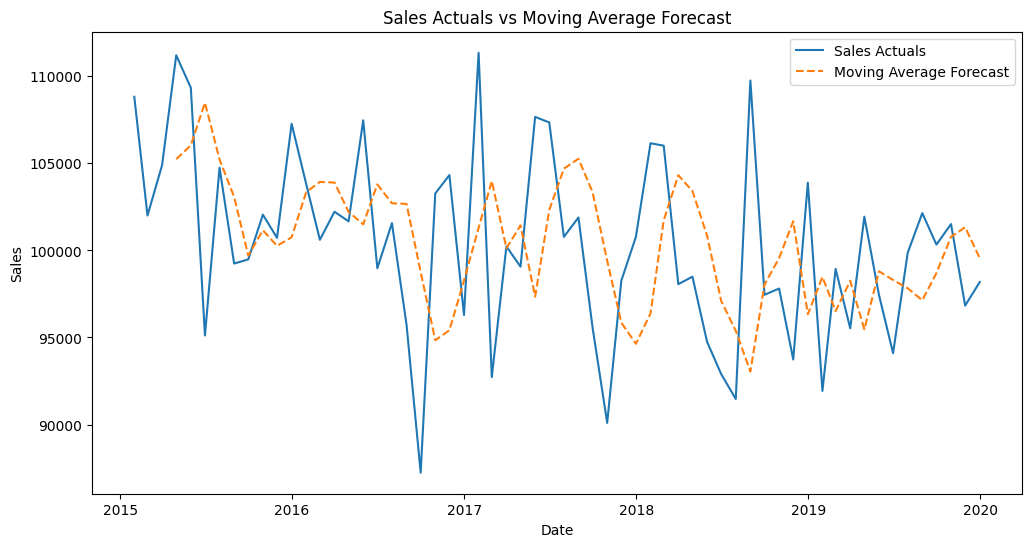

In [18]:
#plot moving average forecast vs sales actuals
plt.figure(figsize=(12,6))
plt.plot(data.index, data['Sales_Actuals'], label='Sales Actuals')
plt.plot(data.index, data['Moving_Average_Forecast'], label='Moving Average Forecast', linestyle='--')
plt.title('Sales Actuals vs Moving Average Forecast')
plt.xlabel('Date')
plt.ylabel('Sales')
plt.legend()
plt.show()

# Weighted Moving Average Forecast

In [19]:
#calculate weighted moving average forecast with window size 3 and weights 0.5, 0.3, 0.2
weights = [0.5, 0.3, 0.2]
data['Weighted_Moving_Average_Forecast'] = data['Sales_Actuals'].rolling(window=3).apply(lambda x: np.dot(x, weights), raw=True).shift(1)
#place columns in order: Sales_Actuals, Weighted_Moving_Average_Forecast, Moving_Average_Forecast, Simple_Average_Forecast, Naive_Forecast
data = data[['Sales_Actuals', 'Weighted_Moving_Average_Forecast', 'Moving_Average_Forecast', 'Simple_Average_Forecast', 'Naive_Forecast']]
data.head(10)

,Sales_Actuals,Weighted_Moving_Average_Forecast,Moving_Average_Forecast,Simple_Average_Forecast,Naive_Forecast
date,,,,,
2015-01-31,108820,NaN,NaN,NaN,NaN
2015-02-28,102001,NaN,NaN,108820.000000,108820.0
2015-03-31,104894,NaN,NaN,105410.500000,102001.0
2015-04-30,111204,105989.1,105238.333333,105238.333333,104894.0
2015-05-31,109338,104709.5,106033.000000,106729.750000,111204.0
2015-06-30,95114,107675.8,108478.666667,107251.400000,109338.0
2015-07-31,104750,107426.2,105218.666667,105228.500000,95114.0
2015-08-31,99243,104153.2,103067.333333,105160.142857,104750.0
2015-09-30,99484,98830.6,99702.333333,104420.500000,99243.0


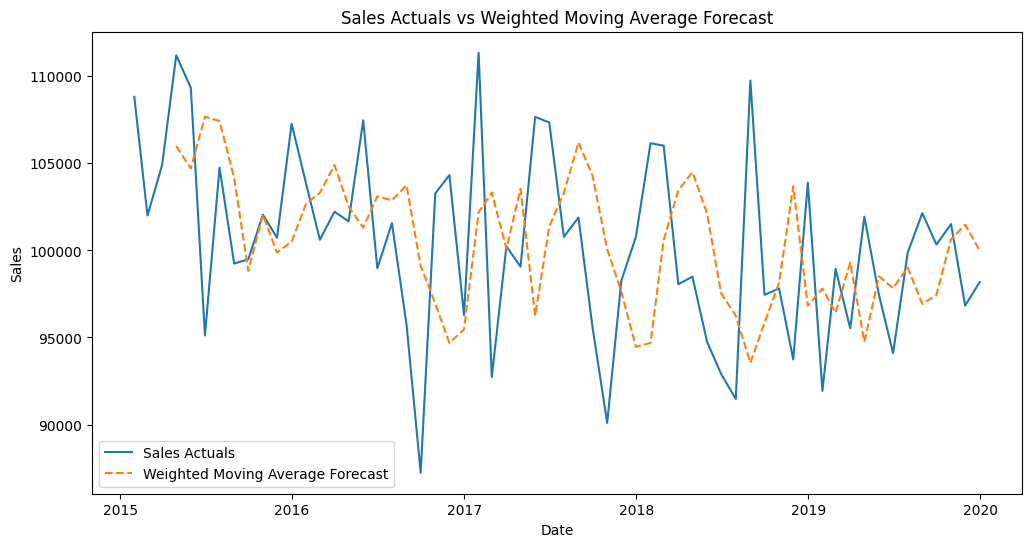

In [20]:
#plot weighted moving average forecast vs sales actuals
plt.figure(figsize=(12,6))
plt.plot(data.index, data['Sales_Actuals'], label='Sales Actuals')
plt.plot(data.index, data['Weighted_Moving_Average_Forecast'], label='Weighted Moving Average Forecast', linestyle='--')
plt.title('Sales Actuals vs Weighted Moving Average Forecast')
plt.xlabel('Date')
plt.ylabel('Sales')
plt.legend()
plt.show()